# Colombo Land Prices: Modelling

Uses the cleaned data from `01_data_preparation.ipynb`.

**Plan**
1. Hold out one listing for the inference demo, then split train/test
2. Baseline: Ridge regression (scaled)
3. Random Forest and XGBoost: default vs tuned
4. Models chosen for this problem: LightGBM, CatBoost and a stacked ensemble
5. Compare, pick the final model, and interpret it
6. Extension: Low / Medium / High price-band classification
7. Save the model (pickle) and run inference on the held-out listing

In [1]:
import pickle
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, StackingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score)
from sklearn.model_selection import KFold, RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMRegressor
from catboost_wrapper import CatBoostAreaRegressor  # see catboost_wrapper.py for why

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
pd.set_option("display.max_columns", 50)

## 1. Data, features and split

In [2]:
df = pd.read_csv("land_prices_clean.csv", parse_dates=["Posted_Date_new"])

TARGET_RAW, TARGET = "Price per Perch", "log_price_per_perch"
CAT = ["Address"]
print("posting dates:", df["Posted_Date_new"].min().date(), "to", df["Posted_Date_new"].max().date())

FEATURES = [c for c in df.columns if c not in ["Posted_Date_new", TARGET_RAW, TARGET]]
NUM = [c for c in FEATURES if c not in CAT]
print(len(df), "rows,", len(FEATURES), "features")

posting dates: 2021-07-31 to 2021-09-21
4275 rows, 33 features


**Posting date is dropped.** All listings were posted within about 8 weeks (Jul-Sep 2021), too short for
land prices to move meaningfully. Keeping it would mostly let the model memorise noise.

**Address** has about 160 areas. One-hot encoding would add 160 sparse columns, so instead each area is
replaced by its average (log) price with scikit-learn's `TargetEncoder`. It uses internal cross-fitting, so a
row's own price never leaks into its encoding. CatBoost handles the area column natively.

In [3]:
# Inference demo: one listing the models never see during training or testing
holdout = df.sample(1, random_state=SEED)
data = df.drop(holdout.index).reset_index(drop=True)

# Stratify on price thirds so train and test cover cheap and expensive land equally
strata = pd.qcut(data[TARGET], 3, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    data[FEATURES], data[TARGET], test_size=0.2, random_state=SEED, stratify=strata)
print("train:", X_train.shape, " test:", X_test.shape)
holdout[["Address", "Land_size(Perches)", TARGET_RAW]]

train: (3419, 33)  test: (855, 33)


,Address,Land_size(Perches),Price per Perch
3907,dampe,9.7,300000.0


## 2. Shared helpers

All models predict **log** price per perch (see notebook 01 for why). Metrics are reported both on the log
scale and converted back to rupees, since rupees are what a buyer cares about.

Model **selection** uses 5-fold cross-validation on the training set only. The test set is used once at the end
of each model, so the comparison isn't biased towards whatever happened to suit the test split.

In [4]:
cv = KFold(5, shuffle=True, random_state=SEED)
results, models = {}, {}


def tree_prep():
    return ColumnTransformer(
        [("area", TargetEncoder(target_type="continuous", random_state=SEED), CAT)],
        remainder="passthrough")


def evaluate(name, model, cv_rmse):
    pred_log = model.predict(X_test)
    actual, pred = np.expm1(y_test), np.expm1(pred_log)
    results[name] = {
        "CV RMSE (log)": cv_rmse,
        "Test RMSE (log)": np.sqrt(mean_squared_error(y_test, pred_log)),
        "Test R2 (log)": r2_score(y_test, pred_log),
        "Test MAE (Rs/perch)": mean_absolute_error(actual, pred),
        "Test MAPE": mean_absolute_percentage_error(actual, pred),
        "Test median APE": np.median(np.abs(pred - actual) / actual),
    }
    models[name] = model
    return pd.Series(results[name]).round(3)


def cv_rmse(model):
    return -cross_val_score(model, X_train, y_train, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1).mean()


def tune(pipe, params, n_iter):
    search = RandomizedSearchCV(pipe, params, n_iter=n_iter, cv=cv, random_state=SEED,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    start = time.time()
    search.fit(X_train, y_train)
    print(f"{n_iter} candidates x 5 folds in {time.time() - start:.0f}s")
    print("best CV RMSE (log):", round(-search.best_score_, 4))
    for k, v in search.best_params_.items():
        print(f"  {k.replace('model__', '')}: {v:.4g}" if isinstance(v, float) else f"  {k.replace('model__', '')}: {v}")
    return search.best_estimator_, -search.best_score_

## 3. Baseline: Ridge regression

A linear model is the reference point: if the tree models can't clearly beat it, they aren't worth their
complexity. This is the one model that **needs scaling**, because Ridge's penalty treats every coefficient
equally, so features measured in km and counts of 0-40 must be on the same scale.

In [5]:
ridge = Pipeline([("prep", tree_prep()), ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
ridge.fit(X_train, y_train)
evaluate("Ridge (baseline)", ridge, cv_rmse(ridge))

CV RMSE (log)               0.451
Test RMSE (log)             0.406
Test R2 (log)               0.836
Test MAE (Rs/perch)    594269.912
Test MAPE                   0.288
Test median APE             0.165
dtype: float64

## 4. Random Forest

First with library defaults, then tuned. The search ranges are chosen for this dataset (about 3,400 training
rows, 36 features):

| Parameter | Range | Reason |
|---|---|---|
| `n_estimators` | 200-800 | More trees reduce variance; beyond a few hundred the gain flattens |
| `max_depth` | 10-30 or unlimited | Limits how specific each tree gets; unlimited trees can memorise individual listings |
| `min_samples_leaf` | 1-8 | Prices are noisy (asking prices, not sale prices), so leaves of 1 listing may fit noise |
| `max_features` | 30-100% | Many features are correlated (e.g. distance to Fort vs. bank counts); sampling fewer per split de-correlates the trees |
| `max_samples` | 70%-100% | Smaller bootstrap samples add diversity between trees |

In [6]:
rf_default = Pipeline([("prep", tree_prep()), ("model", RandomForestRegressor(random_state=SEED, n_jobs=-1))])
rf_default.fit(X_train, y_train)
evaluate("Random Forest (default)", rf_default, cv_rmse(rf_default))

CV RMSE (log)               0.445
Test RMSE (log)             0.409
Test R2 (log)               0.834
Test MAE (Rs/perch)    537806.748
Test MAPE                   0.243
Test median APE             0.103
dtype: float64

In [7]:
rf_pipe = Pipeline([("prep", tree_prep()), ("model", RandomForestRegressor(random_state=SEED, n_jobs=1))])
rf_params = {
    "model__n_estimators": randint(200, 800),
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_leaf": [1, 2, 3, 5, 8],
    "model__max_features": [0.3, 0.5, 0.7, 1.0],
    "model__max_samples": [0.7, 0.85, None],
}
best_rf, rf_cv = tune(rf_pipe, rf_params, n_iter=25)
evaluate("Random Forest (tuned)", best_rf, rf_cv)

25 candidates x 5 folds in 167s
best CV RMSE (log): 0.4289
  max_depth: 20
  max_features: 0.3
  max_samples: None
  min_samples_leaf: 3
  n_estimators: 271


CV RMSE (log)               0.429
Test RMSE (log)             0.374
Test R2 (log)               0.861
Test MAE (Rs/perch)    552219.642
Test MAPE                   0.231
Test median APE             0.115
dtype: float64

## 5. XGBoost

Boosting builds trees one after another, each fixing the previous one's errors, so the parameters interact
more than in Random Forest:

| Parameter | Range | Reason |
|---|---|---|
| `learning_rate` + `n_estimators` | 0.01-0.2, 300-1500 | Smaller steps need more trees but usually generalise better |
| `max_depth` | 3-8 | Boosted trees should be shallower than RF trees; each only corrects part of the error |
| `min_child_weight` | 1-10 | Stops splits that only describe a handful of listings |
| `subsample`, `colsample_bytree` | 0.6-1.0, 0.5-1.0 | Row/column sampling, as in RF, to reduce overfitting |
| `reg_lambda`, `gamma` | 0.1-10, 0-0.3 | L2 penalty on leaf values and minimum gain needed to split |

In [8]:
xgb_default = Pipeline([("prep", tree_prep()), ("model", XGBRegressor(random_state=SEED, n_jobs=-1))])
xgb_default.fit(X_train, y_train)
evaluate("XGBoost (default)", xgb_default, cv_rmse(xgb_default))

CV RMSE (log)               0.449
Test RMSE (log)             0.414
Test R2 (log)               0.830
Test MAE (Rs/perch)    594944.029
Test MAPE                   0.256
Test median APE             0.110
dtype: float64

In [9]:
xgb_pipe = Pipeline([("prep", tree_prep()), ("model", XGBRegressor(random_state=SEED, n_jobs=1))])
xgb_params = {
    "model__n_estimators": randint(300, 1500),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_depth": randint(3, 9),
    "model__min_child_weight": randint(1, 11),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__reg_lambda": loguniform(0.1, 10),
    "model__gamma": uniform(0, 0.3),
}
best_xgb, xgb_cv = tune(xgb_pipe, xgb_params, n_iter=40)
evaluate("XGBoost (tuned)", best_xgb, xgb_cv)

40 candidates x 5 folds in 104s
best CV RMSE (log): 0.4282
  colsample_bytree: 0.7764
  gamma: 0.1778
  learning_rate: 0.01274
  max_depth: 5
  min_child_weight: 1
  n_estimators: 1066
  reg_lambda: 4.039
  subsample: 0.7881


CV RMSE (log)               0.428
Test RMSE (log)             0.373
Test R2 (log)               0.862
Test MAE (Rs/perch)    561202.630
Test MAPE                   0.242
Test median APE             0.122
dtype: float64

## 6. Models chosen for this problem

The lecturer asked us to go beyond RF and XGBoost and pick models that suit the problem:

- **CatBoost**: the most important categorical feature, `Address`, has about 160 levels. CatBoost encodes
  categories internally with ordered target statistics, designed for exactly this case.
- **LightGBM**: another gradient-boosting library that grows trees leaf-wise. It's a useful check on whether
  XGBoost's result depends on its particular implementation.
- **Stacking**: combines the tuned RF, XGBoost and CatBoost. A Ridge model learns how much to trust each one.
  It helps when the base models make *different* mistakes.

In [10]:
lgbm_pipe = Pipeline([("prep", tree_prep()),
                      ("model", LGBMRegressor(random_state=SEED, n_jobs=1, subsample_freq=1, verbose=-1))])
lgbm_params = {
    "model__n_estimators": randint(300, 1500),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__num_leaves": randint(15, 80),
    "model__min_child_samples": randint(5, 40),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__reg_lambda": loguniform(0.1, 10),
}
best_lgbm, lgbm_cv = tune(lgbm_pipe, lgbm_params, n_iter=30)
evaluate("LightGBM (tuned)", best_lgbm, lgbm_cv)

30 candidates x 5 folds in 80s
best CV RMSE (log): 0.4274
  colsample_bytree: 0.9011
  learning_rate: 0.0125
  min_child_samples: 11
  n_estimators: 820
  num_leaves: 15
  reg_lambda: 0.2497
  subsample: 0.6022


CV RMSE (log)               0.427
Test RMSE (log)             0.373
Test R2 (log)               0.862
Test MAE (Rs/perch)    567464.266
Test MAPE                   0.245
Test median APE             0.135
dtype: float64

In [11]:
cat = CatBoostAreaRegressor(cat_features=tuple(CAT), random_seed=SEED, thread_count=1)
cat_params = {
    "iterations": [800, 1200],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.06, 0.1],
    "l2_leaf_reg": [1, 3, 5, 10],
}
best_cat, cat_cv = tune(cat, cat_params, n_iter=12)
evaluate("CatBoost (tuned)", best_cat, cat_cv)

12 candidates x 5 folds in 1208s
best CV RMSE (log): 0.4311
  learning_rate: 0.03
  l2_leaf_reg: 5
  iterations: 800
  depth: 8


CV RMSE (log)               0.431
Test RMSE (log)             0.368
Test R2 (log)               0.866
Test MAE (Rs/perch)    565099.186
Test MAPE                   0.240
Test median APE             0.123
dtype: float64

In [12]:
stack = StackingRegressor(
    estimators=[("rf", best_rf), ("xgb", best_xgb), ("cat", best_cat)],
    final_estimator=RidgeCV(), cv=5, n_jobs=-1)
stack_cv = cv_rmse(stack)
stack.fit(X_train, y_train)
print("stacking weights (rf, xgb, cat):", stack.final_estimator_.coef_.round(3))
evaluate("Stacking (RF + XGB + Cat)", stack, stack_cv)

stacking weights (rf, xgb, cat): [0.473 0.224 0.301]


CV RMSE (log)               0.427
Test RMSE (log)             0.368
Test R2 (log)               0.866
Test MAE (Rs/perch)    554620.134
Test MAPE                   0.232
Test median APE             0.118
dtype: float64

## 7. Comparison

In [13]:
res = pd.DataFrame(results).T.sort_values("CV RMSE (log)")
res.style.format({"Test MAE (Rs/perch)": "{:,.0f}", "Test MAPE": "{:.1%}", "Test median APE": "{:.1%}"},
                 precision=4).highlight_min(subset=["CV RMSE (log)", "Test RMSE (log)"], color="#cfe8cf")

,CV RMSE (log),Test RMSE (log),Test R2 (log),Test MAE (Rs/perch),Test MAPE,Test median APE
Stacking (RF + XGB + Cat),0.4265,0.3677,0.8661,"554,620",23.2%,11.8%
LightGBM (tuned),0.4274,0.3726,0.8624,"567,464",24.5%,13.5%
XGBoost (tuned),0.4282,0.3729,0.8622,"561,203",24.2%,12.2%
Random Forest (tuned),0.4289,0.3742,0.8613,"552,220",23.1%,11.5%
CatBoost (tuned),0.4311,0.3677,0.8660,"565,099",24.0%,12.3%
Random Forest (default),0.4450,0.4092,0.8341,"537,807",24.3%,10.3%
XGBoost (default),0.4490,0.4138,0.8304,"594,944",25.6%,11.0%
Ridge (baseline),0.4509,0.4063,0.8364,"594,270",28.8%,16.5%


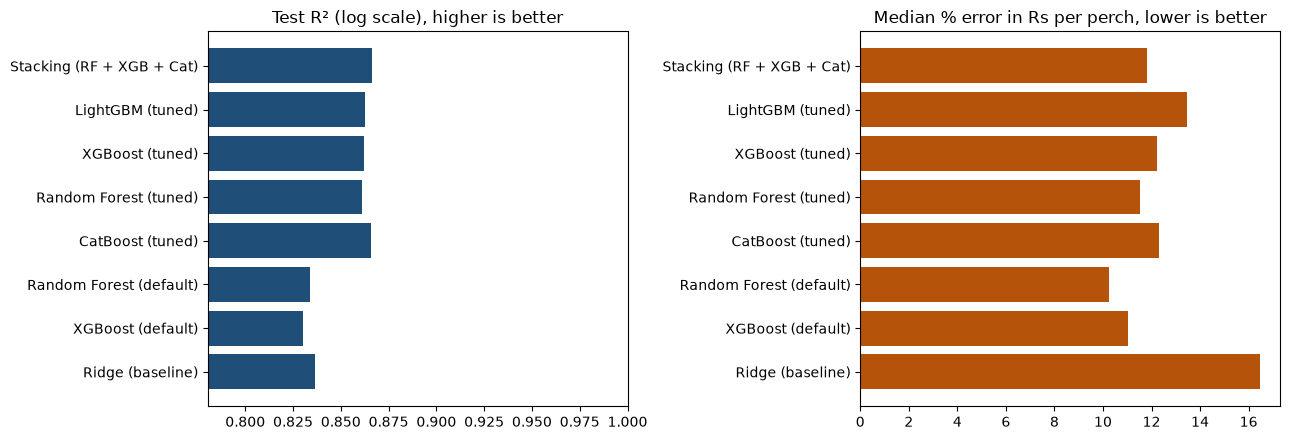

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
order = res.index[::-1]
ax[0].barh(order, res.loc[order, "Test R2 (log)"], color="#1F4E79")
ax[0].set_xlim(res["Test R2 (log)"].min() - 0.05, 1)
ax[0].set_title("Test R² (log scale), higher is better")
ax[1].barh(order, res.loc[order, "Test median APE"] * 100, color="#B45309")
ax[1].set_title("Median % error in Rs per perch, lower is better")
plt.tight_layout()

final model: Stacking (RF + XGB + Cat)


Text(0.5, 1.0, 'Stacking (RF + XGB + Cat): predicted vs actual (test set)')

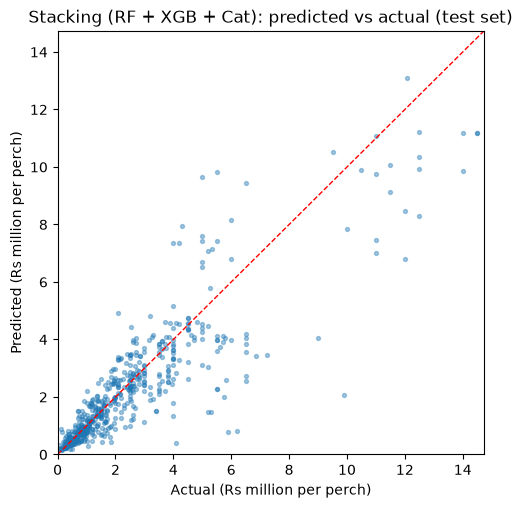

In [15]:
# Selected on cross-validation (training data only), not on the test set
FINAL = res["CV RMSE (log)"].idxmin()
final_model = models[FINAL]
print("final model:", FINAL)

pred = np.expm1(final_model.predict(X_test))
actual = np.expm1(y_test)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(actual / 1e6, pred / 1e6, s=8, alpha=0.4)
lim = [0, np.percentile(actual / 1e6, 99)]
plt.plot(lim, lim, "r--", lw=1)
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("Actual (Rs million per perch)"); plt.ylabel("Predicted (Rs million per perch)")
plt.title(f"{FINAL}: predicted vs actual (test set)")

## 8. Which features drive the price?

**Permutation importance**: shuffle one feature in the test set and measure how much worse the predictions get.
Unlike the built-in importances, it works the same for every model type, and it measures what the model
relies on for unseen data.

Distance from fort               0.1739
Address                          0.1218
min_dist_govtschools_a           0.0438
Land_size(Perches)               0.0391
count_banks_within_2km           0.0186
is_Commercial                    0.0153
min_dist_nearest_Pvt_Hospital    0.0120
is_Residential                   0.0111
is_Agricultural                  0.0087
min_dist_intlschools             0.0074
dtype: float64

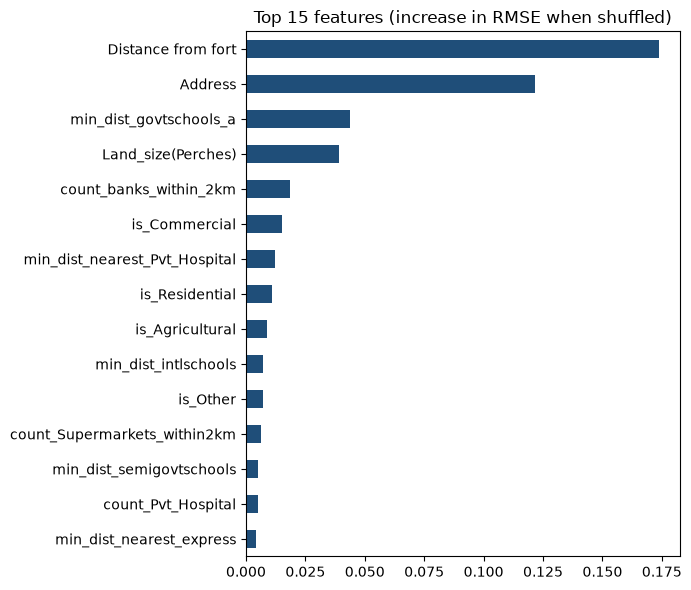

In [16]:
imp = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=SEED,
                             scoring="neg_root_mean_squared_error", n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
importance.head(15)[::-1].plot.barh(figsize=(7, 6), color="#1F4E79",
                                    title="Top 15 features (increase in RMSE when shuffled)")
plt.tight_layout()
importance.head(10).round(4)

In [17]:
# Direction of the strongest location effects, read from the data itself
for col in ["Distance from fort", "min_dist_nearest_railway", "count_banks_within_2km", "Land_size(Perches)"]:
    bins = pd.qcut(data[col], 4, duplicates="drop")
    print(f"\n{col}: median Rs/perch by quartile")
    print(data.groupby(bins, observed=True)[TARGET_RAW].median().map("{:,.0f}".format).to_string())


Distance from fort: median Rs/perch by quartile
Distance from fort
(3.379, 12.764]     3,749,020
(12.764, 18.237]    1,425,000
(18.237, 22.484]      884,923
(22.484, 42.887]      437,500

min_dist_nearest_railway: median Rs/perch by quartile
min_dist_nearest_railway
(0.0185, 1.083]    2,600,000
(1.083, 3.931]     1,650,000
(3.931, 6.74]        900,000
(6.74, 29.987]       440,000

count_banks_within_2km: median Rs/perch by quartile
count_banks_within_2km
(-0.001, 2.0]      593,976
(2.0, 8.0]         720,000
(8.0, 14.0]      1,700,000
(14.0, 73.0]     3,700,000

Land_size(Perches): median Rs/perch by quartile
Land_size(Perches)
(0.999, 7.0]       650,000
(7.0, 9.6]         865,500
(9.6, 16.0]      1,497,500
(16.0, 555.0]    2,350,000


## 9. Extension: price-band classification

The same problem, framed as classification: is a listing **Low**, **Medium** or **High** priced? Band edges are
the training set's price thirds, computed from training data only. The area is target-encoded per class.

In [18]:
edges = np.expm1(y_train.quantile([1 / 3, 2 / 3])).values
BANDS = ["Low", "Medium", "High"]
print("band edges (Rs/perch):", [f"{e:,.0f}" for e in edges])

yc_train = np.digitize(np.expm1(y_train), edges)
yc_test = np.digitize(np.expm1(y_test), edges)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)


def clf_prep():
    return ColumnTransformer(
        [("area", TargetEncoder(target_type="multiclass", random_state=SEED), CAT)], remainder="passthrough")


def tune_clf(pipe, params, n_iter):
    search = RandomizedSearchCV(pipe, params, n_iter=n_iter, cv=skf, scoring="f1_macro",
                                random_state=SEED, n_jobs=-1)
    search.fit(X_train, yc_train)
    print("best CV macro-F1:", round(search.best_score_, 4))
    return search.best_estimator_

rf_clf = tune_clf(
    Pipeline([("prep", clf_prep()), ("model", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
    {"model__n_estimators": randint(200, 800), "model__max_depth": [None, 10, 15, 20],
     "model__min_samples_leaf": [1, 2, 4, 8], "model__max_features": [0.3, 0.5, 0.7]}, n_iter=20)
xgb_clf = tune_clf(
    Pipeline([("prep", clf_prep()), ("model", XGBClassifier(random_state=SEED, n_jobs=1))]),
    {k: v for k, v in xgb_params.items()}, n_iter=30)

band edges (Rs/perch): ['672,486', '1,800,000']


best CV macro-F1: 0.8748


best CV macro-F1: 0.8744


,Accuracy,Macro F1
Random Forest classifier,0.905,0.905
XGBoost classifier,0.897,0.896
Stacking (RF + XGB + Cat) regression -> band,0.892,0.892


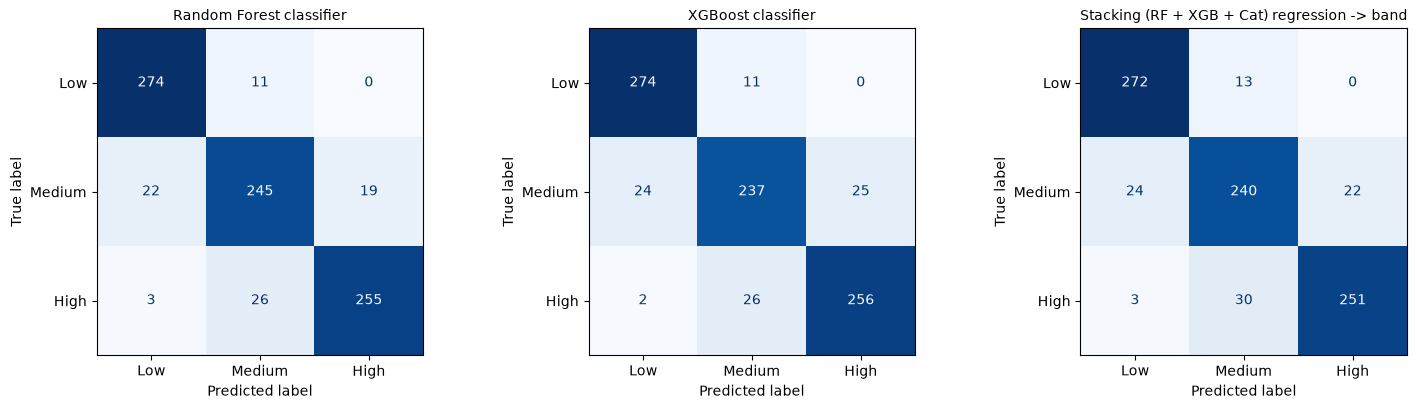

In [19]:
clf_results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
candidates = {
    "Random Forest classifier": rf_clf.predict(X_test),
    "XGBoost classifier": xgb_clf.predict(X_test),
    f"{FINAL} regression -> band": np.digitize(np.expm1(final_model.predict(X_test)), edges),
}
for ax, (name, p) in zip(axes, candidates.items()):
    clf_results[name] = {"Accuracy": accuracy_score(yc_test, p), "Macro F1": f1_score(yc_test, p, average="macro")}
    ConfusionMatrixDisplay.from_predictions(yc_test, p, display_labels=BANDS, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
pd.DataFrame(clf_results).T.round(3)

In [20]:
best_clf_name = max(["Random Forest classifier", "XGBoost classifier"], key=lambda n: clf_results[n]["Macro F1"])
best_clf = rf_clf if best_clf_name.startswith("Random") else xgb_clf
print(best_clf_name)
print(classification_report(yc_test, best_clf.predict(X_test), target_names=BANDS))

Random Forest classifier
              precision    recall  f1-score   support

         Low       0.92      0.96      0.94       285
      Medium       0.87      0.86      0.86       286
        High       0.93      0.90      0.91       284

    accuracy                           0.91       855
   macro avg       0.91      0.91      0.91       855
weighted avg       0.91      0.91      0.90       855



## 10. Save the model and run inference

Everything the front-end needs goes into one pickle: both models, the feature order, the band edges, and each
area's typical location values so the app can pre-fill them.

In [21]:
LAND_TYPES = [c for c in FEATURES if c.startswith("is_")]
bundle = {
    "regressor": final_model,
    "regressor_name": FINAL,
    "classifier": best_clf,
    "classifier_name": best_clf_name,
    "band_edges": edges,
    "band_labels": BANDS,
    "features": FEATURES,
    "land_types": LAND_TYPES,
    "area_defaults": data.groupby("Address")[NUM].median(),
    "test_metrics": results[FINAL],
}
with open("land_price_model.pkl", "wb") as f:
    pickle.dump(bundle, f)
print("saved land_price_model.pkl")

saved land_price_model.pkl

In [22]:
# Inference on the held-out listing, loading the model back from disk as the app would
with open("land_price_model.pkl", "rb") as f:
    loaded = pickle.load(f)

x_new = holdout[loaded["features"]]
pred_ppp = np.expm1(loaded["regressor"].predict(x_new))[0]
band = loaded["band_labels"][loaded["classifier"].predict(x_new)[0]]
actual_ppp = holdout[TARGET_RAW].iloc[0]
size = holdout["Land_size(Perches)"].iloc[0]

print(f"Listing: {holdout['Address'].iloc[0]}, {size:g} perches")
print(f"Actual price per perch:    Rs {actual_ppp:,.0f}")
print(f"Predicted price per perch: Rs {pred_ppp:,.0f}  ({(pred_ppp - actual_ppp) / actual_ppp:+.1%})")
print(f"Predicted total price:     Rs {pred_ppp * size:,.0f}")
print(f"Predicted price band:      {band}")

Listing: dampe, 9.7 perches
Actual price per perch:    Rs 300,000
Predicted price per perch: Rs 332,620  (+10.9%)
Predicted total price:     Rs 3,226,419
Predicted price band:      Low


## 11. Summary

- **Tuning mattered:** RF CV RMSE 0.445 to 0.429, XGBoost 0.449 to 0.428; test R² about 0.83 to 0.86.
- **The tuned models are almost tied** (within 0.005 CV RMSE). Stacking is best on CV (0.4265) and was chosen;
  test R² 0.866, median error about 12%.
- **Location dominates.** Distance from Fort and Address are the top features, but they carry the same
  information, because every location feature is constant within an area (see `03_unseen_areas.ipynb`).
- **Classification:** the Random Forest classifier reaches 90.5% accuracy on Low/Medium/High; almost all errors
  are between neighbouring bands.
- **Inference:** held-out Dampe listing predicted Rs 332,620/perch against an actual Rs 300,000 (+10.9%).

Full discussion: report Sections 5-7.